# Lesson 3 — Forecasting and Anomaly Detection

**Smarter Campus · Creativity, Science and Innovation · Politecnico di Milano**

**Part A (sections 1–3), with the slide "Example" in the middle of the lesson**
1. load the data and look at six weeks
2. the regression example of the slides: people from CO₂, and overfitting
3. 1st alternative: from a time series to a table (lag features) and a Random Forest

**Part B (sections 4–10), with the slide "Example" at the end**
4. the forecasting task: how many people in 30 minutes?
5. split in time
6. baselines: persistence and seasonal naive
7. a boosted tree on past values and context
8. a small LSTM
9. compare
10. anomaly detection: three anomalies, three methods

**The dataset** (`study_room_6weeks.csv`) is **simulated** for this course: the same 40-seat study room of lesson 2, now for **6 weeks** (2 November – 13 December 2026), 24 hours a day, **one row every 5 minutes**.

| column | meaning |
|---|---|
| `timestamp` | date and time (one row every 5 minutes) |
| `co2_ppm` | CO₂ in parts per million (average over 5 minutes) |
| `pir_triggers` | motion events in the 5 minutes |
| `noise_db` | average sound level (dB) |
| `wifi_devices` | devices connected to the room's Wi-Fi access point |
| `people` | real number of people (ground truth) |
| `lesson_scheduled` | 1 if the timetable says a lesson is booked |

The room is closed at night, at weekends and on **8 December** (public holiday). A few lessons in the timetable did not take place.

In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [4]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

plt.rcParams['figure.figsize'] = (12, 4)
SEED = 0
np.random.seed(SEED)
TEAL, ORANGE, GREY = '#5A8487', '#E8873A', '#9AA5AB'

In [5]:
# Define your desired path
path = '/content/drive/My Drive/CSI_smartcampus26'

# Change the current working directory to the new path
os.chdir(path)

# Verify the current working directory
print("Current Working Directory:", os.getcwd())

Current Working Directory: /content/drive/My Drive/CSI_smartcampus26


# Part A
## 1. Load the data and look at six weeks

In [6]:
df = pd.read_csv('study_room_6weeks.csv', parse_dates=['timestamp']).set_index('timestamp')
df[['co2_ppm', 'noise_db', 'wifi_devices']] = df[['co2_ppm', 'noise_db', 'wifi_devices']].ffill(limit=2)   # short gaps (lesson 1)
print(df.shape, '- from', df.index.min(), 'to', df.index.max())
df.head()

(12096, 6) - from 2026-11-02 00:00:00 to 2026-12-13 23:55:00


,co2_ppm,pir_triggers,noise_db,wifi_devices,people,lesson_scheduled
timestamp,,,,,,
2026-11-02 00:00:00,420.0,0,35.0,2.0,0,0
2026-11-02 00:05:00,413.0,0,35.4,2.0,0,0
2026-11-02 00:10:00,413.0,0,35.9,2.0,0,0
2026-11-02 00:15:00,410.0,0,34.3,2.0,0,0
2026-11-02 00:20:00,413.0,0,33.5,2.0,0,0


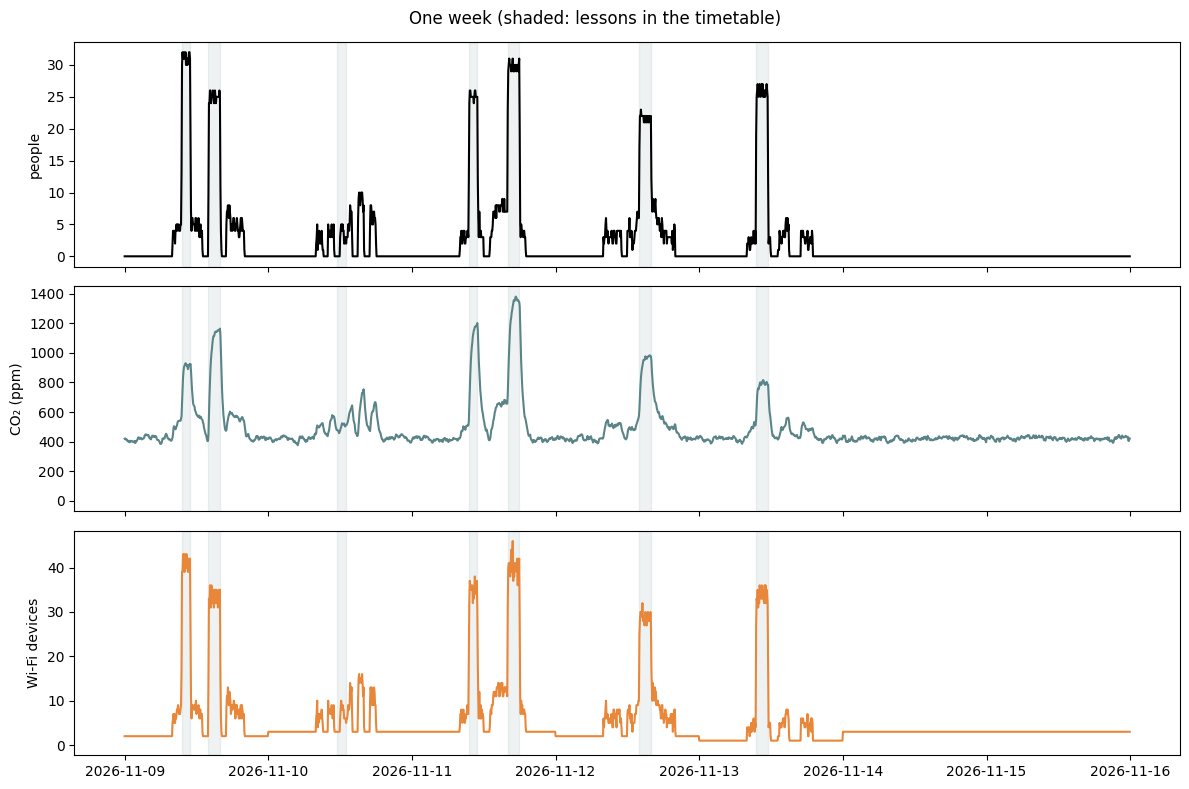

In [7]:
w = df['2026-11-09':'2026-11-15']                      # one full week, Monday to Sunday
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for a in ax:
    a.fill_between(w.index, 0, 1, where=w['lesson_scheduled'] == 1, color=TEAL, alpha=0.1, transform=a.get_xaxis_transform())
ax[0].plot(w.index, w['people'], color='black'); ax[0].set_ylabel('people')
ax[1].plot(w.index, w['co2_ppm'], color=TEAL); ax[1].set_ylabel('CO₂ (ppm)')
ax[2].plot(w.index, w['wifi_devices'], color=ORANGE); ax[2].set_ylabel('Wi-Fi devices')
fig.suptitle('One week (shaded: lessons in the timetable)'); plt.tight_layout(); plt.show()

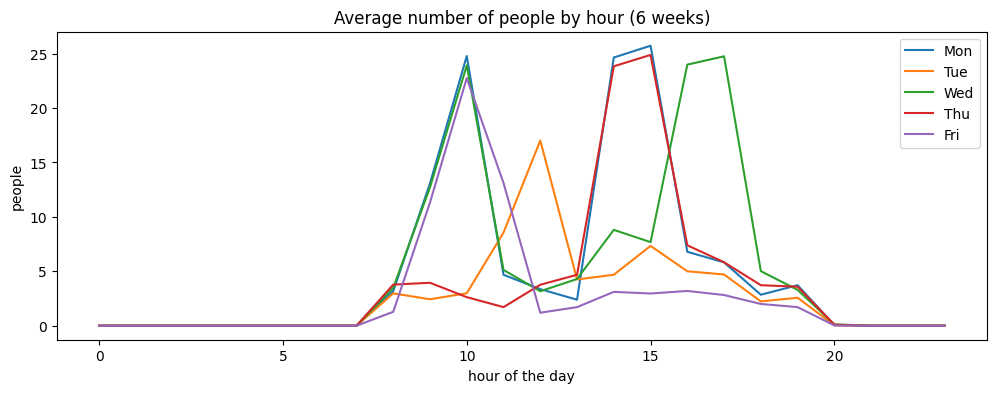

In [8]:
# The average day, by weekday
prof = df.groupby([df.index.dayofweek, df.index.hour])['people'].mean().unstack(0)
prof.columns = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
prof[['Mon', 'Tue', 'Wed', 'Thu', 'Fri']].plot(title='Average number of people by hour (6 weeks)')
plt.ylabel('people'); plt.xlabel('hour of the day'); plt.show()

**Questions for the class**
- Does the week repeat itself? Which days look alike?
- Which signal follows people more closely: CO₂ or Wi-Fi? Which one reacts faster?

## 2. The regression example of the slides: people from CO₂

The slides started from 2 points, then 8, then a curve. Here we do the same with real-looking data.
First **8 windows**, like on the slides: a straight line, a parabola, and a polynomial of degree 7.

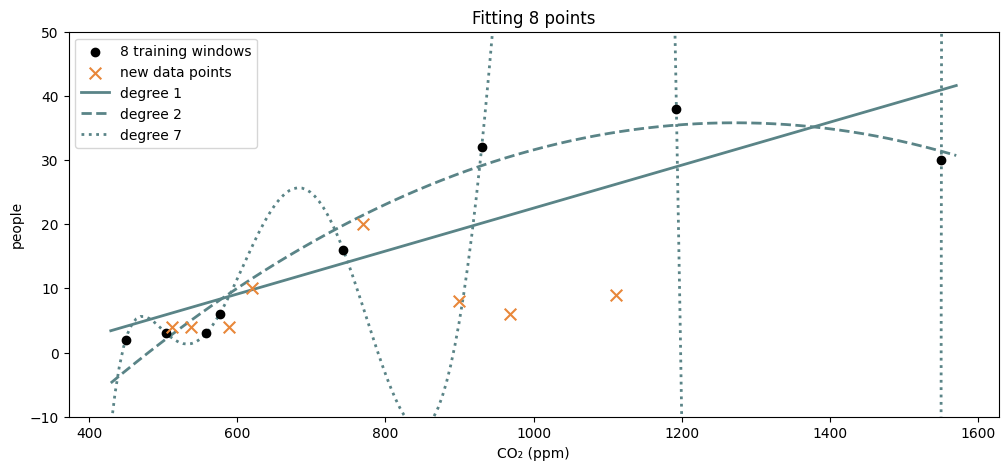

In [9]:
open_hours = df[(df.index.dayofweek < 5) & (df.index.hour >= 8) & (df.index.hour < 20) & (df['people'] > 0)].dropna()
eight = open_hours.sample(8, random_state=3)
new = open_hours.drop(eight.index).sample(8, random_state=4)           # new data points, never seen
x = np.linspace(eight['co2_ppm'].min() - 20, eight['co2_ppm'].max() + 20, 200)

plt.figure(figsize=(12, 5))
plt.scatter(eight['co2_ppm'], eight['people'], color='black', zorder=3, label='8 training windows')
plt.scatter(new['co2_ppm'], new['people'], color=ORANGE, marker='x', s=70, zorder=3, label='new data points')
for deg, style in [(1, '-'), (2, '--'), (7, ':')]:
    coef = np.polyfit((eight['co2_ppm'] - 600) / 100, eight['people'], deg)
    plt.plot(x, np.polyval(coef, (x - 600) / 100), style, color=TEAL, lw=2, label=f'degree {deg}')
plt.ylim(-10, 50); plt.xlabel('CO₂ (ppm)'); plt.ylabel('people'); plt.legend(); plt.title('Fitting 8 points'); plt.show()

Now we repeat it more carefully: we train on **15 windows** from weeks 1–4 and measure the error on **all of week 5**, for polynomials of degree 1 to 8.
Then we train the same polynomials on **all** weeks 1–4.

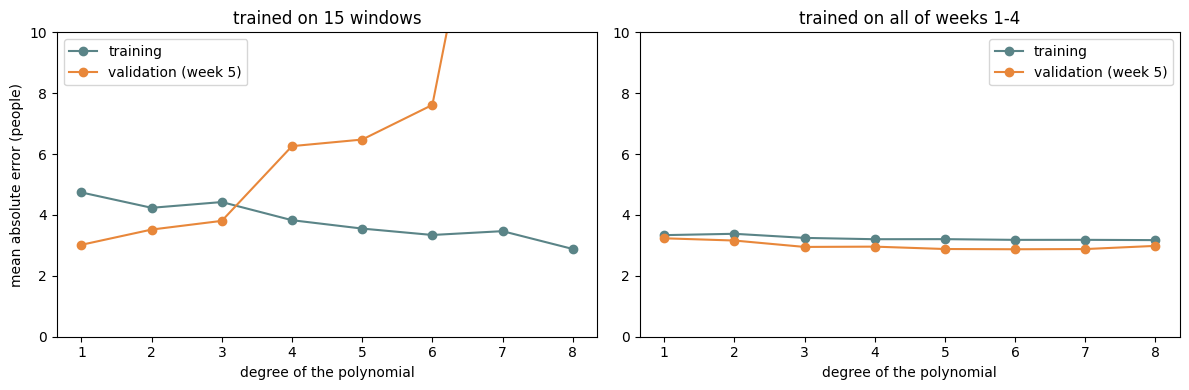

trained on,15 windows,all of weeks 1-4
degree,,
1,3.0,3.2
2,3.5,3.2
3,3.8,2.9
4,6.3,3.0
5,6.5,2.9
6,7.6,2.9
7,19.2,2.9
8,101.0,3.0


In [10]:
tr = open_hours[:'2026-11-29']; va = open_hours['2026-11-30':'2026-12-06']
few = tr.sample(15, random_state=1)
degrees = range(1, 9); rows = []
for deg in degrees:
    for name, data in [('15 windows', few), ('all of weeks 1-4', tr)]:
        coef = np.polyfit((data['co2_ppm'] - 600) / 100, data['people'], deg)
        rows.append({'degree': deg, 'trained on': name,
                     'training': mean_absolute_error(data['people'], np.polyval(coef, (data['co2_ppm'] - 600) / 100)),
                     'validation': mean_absolute_error(va['people'], np.polyval(coef, (va['co2_ppm'] - 600) / 100))})
res = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, name in zip(ax, ['15 windows', 'all of weeks 1-4']):
    r = res[res['trained on'] == name]
    a.plot(r['degree'], r['training'], 'o-', color=TEAL, label='training')
    a.plot(r['degree'], r['validation'], 'o-', color=ORANGE, label='validation (week 5)')
    a.set_title(f'trained on {name}'); a.set_xlabel('degree of the polynomial'); a.set_ylim(0, 10); a.legend()
ax[0].set_ylabel('mean absolute error (people)'); plt.tight_layout(); plt.show()
res.pivot(index='degree', columns='trained on', values='validation').round(1)

**Questions for the class**
- With 8 points, which curve would you trust? What happens to the degree-7 curve outside the points?
- With 15 windows, where does the validation error start to grow? With all the data, does it still happen?
- Why does the error never go below ~3 people? (CO₂ is slow: it tells how many people *were* there.)

## 3. First alternative: from a time series to a table

Instead of the CO₂ *now*, we give the model a **table** with what happened in the last hour: values 5, 15, 30 and 60 minutes ago (**lag features**) and averages over the last 30 minutes (**rolling features**).
Model: a **Random Forest**, estimating the number of people **now** from **CO₂, noise and motion** only.
(We leave Wi-Fi out on purpose: it counts phones and laptops, so it almost gives the answer. We will use it in Part B.)

In [11]:
def lag_table(df):
    t = pd.DataFrame(index=df.index)
    for c in ['co2_ppm', 'noise_db', 'pir_triggers']:
        t[c] = df[c]
        for k in [1, 3, 6, 12]:                               # 5, 15, 30, 60 minutes ago
            t[f'{c}_lag{k}'] = df[c].shift(k)
        t[f'{c}_mean30'] = df[c].rolling(6).mean()             # average of the last 30 minutes
    t['co2_slope'] = (df['co2_ppm'] - df['co2_ppm'].shift(6)) / 30
    t['hour'] = df.index.hour + df.index.minute / 60
    t['weekday'] = df.index.dayofweek
    t['people'] = df['people']
    return t.dropna()

L = lag_table(df)
train_A, test_A = L[:'2026-12-06'], L['2026-12-07':]
X_cols = [c for c in L.columns if c != 'people']
print(L.shape[1] - 1, 'features from 3 sensors')
L[['co2_ppm', 'co2_ppm_lag1', 'co2_ppm_lag3', 'co2_ppm_mean30', 'co2_slope', 'people']].head()

21 features from 3 sensors


,co2_ppm,co2_ppm_lag1,co2_ppm_lag3,co2_ppm_mean30,co2_slope,people
timestamp,,,,,,
2026-11-02 01:00:00,404.0,402.0,419.0,408.500000,-0.133333,0
2026-11-02 01:05:00,398.0,404.0,409.0,406.666667,-0.366667,0
2026-11-02 01:10:00,408.0,398.0,402.0,406.666667,0.000000,0
2026-11-02 01:15:00,416.0,408.0,404.0,406.166667,-0.100000,0
2026-11-02 01:20:00,419.0,416.0,398.0,407.833333,0.333333,0


Linear regression, CO₂ only:     MAE = 1.86 people
Random Forest, lag table:        MAE = 0.93 people


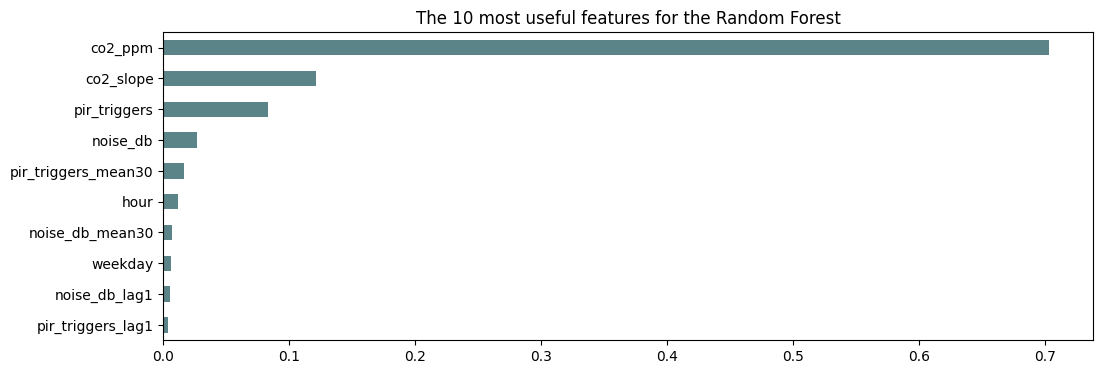

In [12]:
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
rf.fit(train_A[X_cols], train_A['people'])
lin = LinearRegression().fit(train_A[['co2_ppm']], train_A['people'])
day_A = test_A[(test_A['hour'] >= 8) & (test_A['hour'] < 20)]
print(f"Linear regression, CO₂ only:     MAE = {mean_absolute_error(day_A['people'], lin.predict(day_A[['co2_ppm']])):.2f} people")
print(f"Random Forest, lag table:        MAE = {mean_absolute_error(day_A['people'], rf.predict(day_A[X_cols])):.2f} people")

imp = pd.Series(rf.feature_importances_, index=X_cols).sort_values().tail(10)
imp.plot.barh(color=TEAL); plt.title('The 10 most useful features for the Random Forest'); plt.show()

**Questions for the class**
- Which features does the Random Forest use most? Are they the *current* values or the past ones?
- Which sensor matters more: the slow one (CO₂) or the fast ones (noise, motion)?
- Wi-Fi would make this almost perfect. Would it work in your room? What about privacy?

# Part B
## 4. The forecasting task

At time *t* we want the number of people at **t + 30 minutes** (H = 6 steps of 5 minutes).
Inputs available at time *t*: the **past** (people, CO₂, Wi-Fi in the last hour), the **context** (hour, weekday, and the **timetable**: is a lesson booked at t + 30 min?) and **last week** (people in the same slot 7 days ago).

In [13]:
H = 6                       # 6 × 5 min = 30 minutes ahead
WEEK = 7 * 24 * 12          # 5-minute steps in a week

def make_table(df, H=H):
    t = pd.DataFrame(index=df.index)
    for k in [0, 1, 2, 3, 6, 12]:
        t[f'people_lag{k}'] = df['people'].shift(k)
    t['co2'] = df['co2_ppm']
    t['co2_slope'] = (df['co2_ppm'] - df['co2_ppm'].shift(6)) / 30
    t['wifi'] = df['wifi_devices']
    t['wifi_lag6'] = df['wifi_devices'].shift(6)
    t['hour'] = df.index.hour + df.index.minute / 60
    t['weekday'] = df.index.dayofweek
    t['last_week'] = df['people'].shift(WEEK - H)          # people at t + H, one week earlier
    t['lesson_next'] = df['lesson_scheduled'].shift(-H)     # the timetable is known in advance (no lessons on holidays)
    t['target'] = df['people'].shift(-H)
    return t

T = make_table(df).dropna(subset=['people_lag12', 'co2', 'wifi', 'lesson_next', 'target'])
FEATURES = [c for c in T.columns if c != 'target']
T.head()

,people_lag0,people_lag1,people_lag2,people_lag3,people_lag6,people_lag12,co2,co2_slope,wifi,wifi_lag6,hour,weekday,last_week,lesson_next,target
timestamp,,,,,,,,,,,,,,,
2026-11-02 01:00:00,0,0.0,0.0,0.0,0.0,0.0,404.0,-0.133333,2.0,2.0,1.000000,0,NaN,0.0,0.0
2026-11-02 01:05:00,0,0.0,0.0,0.0,0.0,0.0,398.0,-0.366667,2.0,2.0,1.083333,0,NaN,0.0,0.0
2026-11-02 01:10:00,0,0.0,0.0,0.0,0.0,0.0,408.0,0.000000,2.0,2.0,1.166667,0,NaN,0.0,0.0
2026-11-02 01:15:00,0,0.0,0.0,0.0,0.0,0.0,416.0,-0.100000,2.0,2.0,1.250000,0,NaN,0.0,0.0
2026-11-02 01:20:00,0,0.0,0.0,0.0,0.0,0.0,419.0,0.333333,2.0,2.0,1.333333,0,NaN,0.0,0.0


## 5. Split in time

- **train:** weeks 1–5 (2 November – 6 December)
- **test:** week 6 (7 – 13 December), which contains the **8 December holiday**
- we evaluate only on **weekdays, 8:00–20:00**, when the room can be open

In [14]:
train, test = T[:'2026-12-06'], T['2026-12-07':]
OPEN = lambda x: x[(x.index.dayofweek < 5) & (x['hour'] >= 8) & (x['hour'] < 20)]
ev = OPEN(test).dropna(subset=['last_week']).index
print(len(train), 'training rows,', len(ev), 'test rows during opening hours')

10068 training rows, 720 test rows during opening hours


## 6. Baselines first

- **Persistence:** in 30 minutes the room will be as it is now.
- **Seasonal naive:** as it was in the same slot last week.

In [15]:
pred = pd.DataFrame(index=test.index)
pred['real'] = test['target']
pred['persistence'] = test['people_lag0']
pred['seasonal naive'] = test['last_week']
results = {m: mean_absolute_error(pred.loc[ev, 'real'], pred.loc[ev, m]) for m in ['persistence', 'seasonal naive']}
pd.Series(results).round(2).rename('MAE (people)')

,MAE (people)
persistence,2.97
seasonal naive,4.08


## 7. A boosted tree on past values and context

The same family as XGBoost. It handles missing `last_week` values by itself.

In [16]:
gbt = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)
gbt.fit(train[FEATURES], train['target'])
pred['boosted tree'] = gbt.predict(test[FEATURES])
results['boosted tree'] = mean_absolute_error(pred.loc[ev, 'real'], pred.loc[ev, 'boosted tree'])
pd.Series(results).round(2).rename('MAE (people)')

,MAE (people)
persistence,2.97
seasonal naive,4.08
boosted tree,2.55


## 8. A small LSTM

It reads the **last hour** (12 steps) of people, CO₂, Wi-Fi and time of day, and predicts the number of people 30 minutes later.
Results change a little from run to run: neural networks start from random weights.

In [17]:
import tensorflow as tf
tf.random.set_seed(SEED)

Lw = 12
seq = pd.DataFrame(index=df.index)
seq['people'] = df['people']; seq['co2'] = df['co2_ppm']; seq['wifi'] = df['wifi_devices']
hour = df.index.hour + df.index.minute / 60
seq['hour_sin'] = np.sin(2 * np.pi * hour / 24); seq['hour_cos'] = np.cos(2 * np.pi * hour / 24)
seq['weekend'] = (df.index.dayofweek >= 5).astype(float)
seq['lesson_next'] = df['lesson_scheduled'].shift(-H)              # timetable, known in advance
mu, sd = seq[:'2026-12-06'].mean(), seq[:'2026-12-06'].std()         # scale with training statistics only
Z = ((seq - mu) / sd).to_numpy(dtype='float32')
y_all = df['people'].shift(-H).to_numpy(dtype='float32')
pos = {t: i for i, t in enumerate(df.index)}

def windows(index):
    X, y, keep = [], [], []
    for t in index:
        i = pos[t]; x = Z[i - Lw + 1:i + 1]
        if i >= Lw - 1 and not np.isnan(x).any() and not np.isnan(y_all[i]):
            X.append(x); y.append(y_all[i]); keep.append(t)
    return np.array(X), np.array(y), pd.Index(keep)

Xtr, ytr, _ = windows(train.index)
Xte, yte, idx_te = windows(test.index)
lstm = tf.keras.Sequential([tf.keras.layers.Input(shape=(Lw, Xtr.shape[2])),
                            tf.keras.layers.LSTM(32),
                            tf.keras.layers.Dense(16, activation='relu'),
                            tf.keras.layers.Dense(1)])
lstm.compile(optimizer='adam', loss='mae')
hist = lstm.fit(Xtr, ytr, validation_split=0.15, epochs=30, batch_size=64, verbose=0)
print('parameters:', lstm.count_params())
pred.loc[idx_te, 'LSTM'] = lstm.predict(Xte, verbose=0).ravel()
results['LSTM'] = mean_absolute_error(pred.loc[ev, 'real'], pred.loc[ev, 'LSTM'])
pd.Series(results).round(2).rename('MAE (people)')

parameters: 5665


,MAE (people)
persistence,2.97
seasonal naive,4.08
boosted tree,2.55
LSTM,2.08


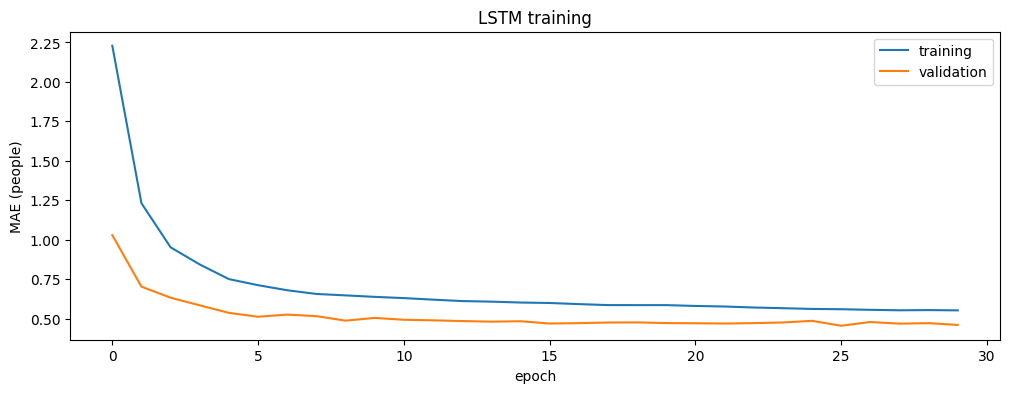

In [18]:
plt.plot(hist.history['loss'], label='training'); plt.plot(hist.history['val_loss'], label='validation')
plt.xlabel('epoch'); plt.ylabel('MAE (people)'); plt.legend(); plt.title('LSTM training'); plt.show()

## 9. Compare

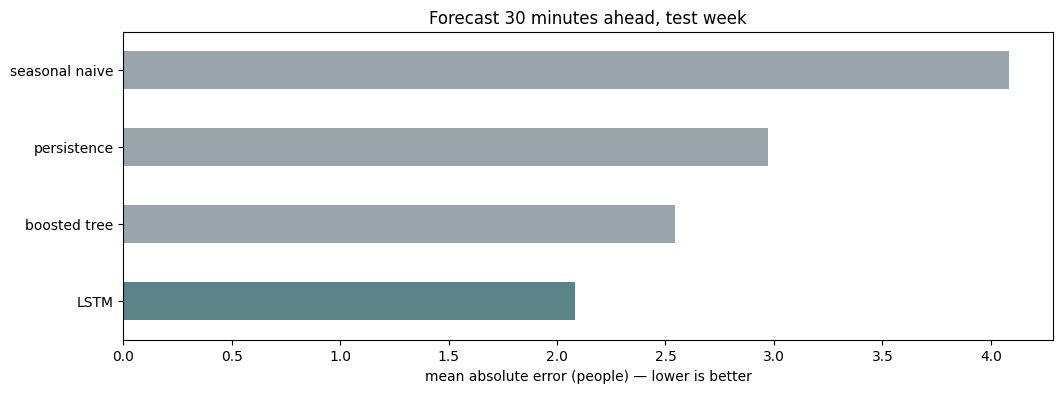

In [19]:
order = pd.Series(results).sort_values()
order.plot.barh(color=[TEAL if i == 0 else GREY for i in range(len(order))])
plt.xlabel('mean absolute error (people) — lower is better'); plt.title('Forecast 30 minutes ahead, test week'); plt.show()

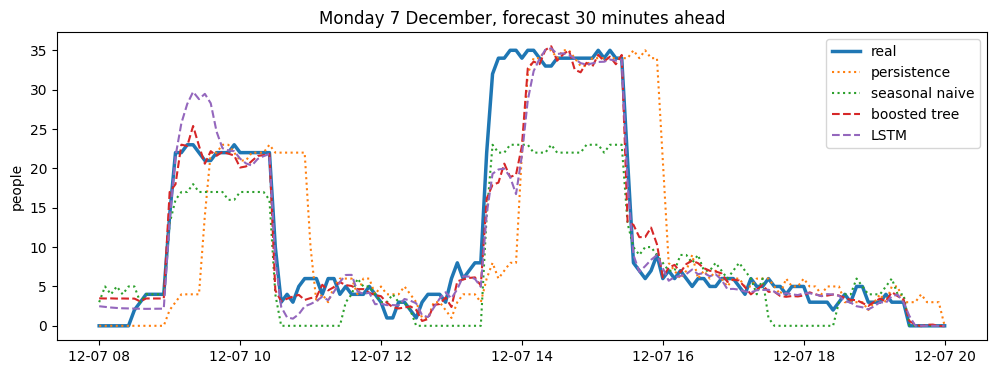

In [20]:
d = pred['2026-12-07 08:00':'2026-12-07 20:00']
for m, style in [('real', '-'), ('persistence', ':'), ('seasonal naive', ':'), ('boosted tree', '--'), ('LSTM', '--')]:
    plt.plot(d.index, d[m], style, label=m, lw=2.5 if m == 'real' else 1.5)
plt.ylabel('people'); plt.legend(); plt.title('Monday 7 December, forecast 30 minutes ahead'); plt.show()

In [21]:
# Error day by day: what happens on the 8 December holiday?
e = pred.loc[ev]
daily = e.groupby(e.index.date).apply(lambda g: pd.Series({m: mean_absolute_error(g['real'], g[m]) for m in results}))
daily.round(2)

,persistence,seasonal naive,boosted tree,LSTM
2026-12-07,4.93,4.39,1.95,2.05
2026-12-08,0.00,5.47,3.02,2.36
2026-12-09,5.12,3.49,2.23,1.55
2026-12-10,3.78,2.44,2.16,1.95
2026-12-11,1.03,4.63,3.36,2.49


**Questions for the class**
- Which model wins? By how much over the baselines? Is the LSTM worth it on a small board?
- What happens on 8 December? Why does the seasonal naive fail, and why do the others not?

## 10. Anomaly detection

We take the test week and **inject three anomalies**, one of each type:
1. **point:** a CO₂ reading of 9790 ppm
2. **contextual:** 20 people in the room at 3 a.m. for one hour
3. **collective:** the CO₂ sensor stuck on the same value for two hours

In [22]:
a = df['2026-12-07':].copy()
injected = {
    'point (CO₂ 9790 ppm)':       pd.date_range('2026-12-09 11:00', periods=1, freq='5min'),
    'contextual (people at 3am)': pd.date_range('2026-12-10 03:00', periods=12, freq='5min'),
    'collective (stuck sensor)':  pd.date_range('2026-12-11 08:30', periods=24, freq='5min'),
}
a.loc[injected['point (CO₂ 9790 ppm)'], 'co2_ppm'] = 9790
a.loc[injected['contextual (people at 3am)'], 'people'] = 20
a.loc[injected['collective (stuck sensor)'], 'co2_ppm'] = a.at[pd.Timestamp('2026-12-11 08:30'), 'co2_ppm']

**Method 1 — z-score** (lesson 1): more than 3 standard deviations from the training mean.

In [23]:
stats = df[:'2026-12-06'].agg(['mean', 'std'])
flag_z = {'co2': ((a['co2_ppm'] - stats.loc['mean', 'co2_ppm']) / stats.loc['std', 'co2_ppm']).abs() > 3,
          'people': ((a['people'] - stats.loc['mean', 'people']) / stats.loc['std', 'people']).abs() > 3}

**Method 2 — forecast residuals**: the boosted tree of section 7 forecasts the number of people; if reality is much farther from the forecast than usual, it is an anomaly.

In [24]:
Ta = make_table(a)
fc = pd.Series(gbt.predict(Ta[FEATURES]), index=Ta.index).shift(H, freq='5min')      # forecast made 30 min before
resid = (a['people'] - fc).reindex(a.index)
clean_resid = (df['people'] - pd.Series(gbt.predict(test[FEATURES]), index=test.index).shift(H, freq='5min')).dropna()
threshold = clean_resid.abs().mean() + 3 * clean_resid.abs().std()
flag_res = {'people': resid.abs() > threshold}
print(f'threshold: {threshold:.1f} people')

threshold: 7.9 people


**Method 3 — a rule for stuck sensors**: a real CO₂ sensor always moves a little. If it does not change at all for one hour, something is wrong.

In [25]:
flag_stuck = {'co2': (a['co2_ppm'].rolling(12).max() - a['co2_ppm'].rolling(12).min()) == 0}

In [26]:
signal = {'point (CO₂ 9790 ppm)': 'co2', 'contextual (people at 3am)': 'people', 'collective (stuck sensor)': 'co2'}
methods = {'z-score': flag_z, 'forecast residual': flag_res, 'stuck-sensor rule': flag_stuck}
table = pd.DataFrame({name: {m: bool(f[signal[name]][t].any()) if signal[name] in f else False for m, f in methods.items()}
                      for name, t in injected.items()}).T
table.replace({True: 'found', False: '—'})

,z-score,forecast residual,stuck-sensor rule
point (CO₂ 9790 ppm),found,—,—
contextual (people at 3am),—,found,—
collective (stuck sensor),—,—,found


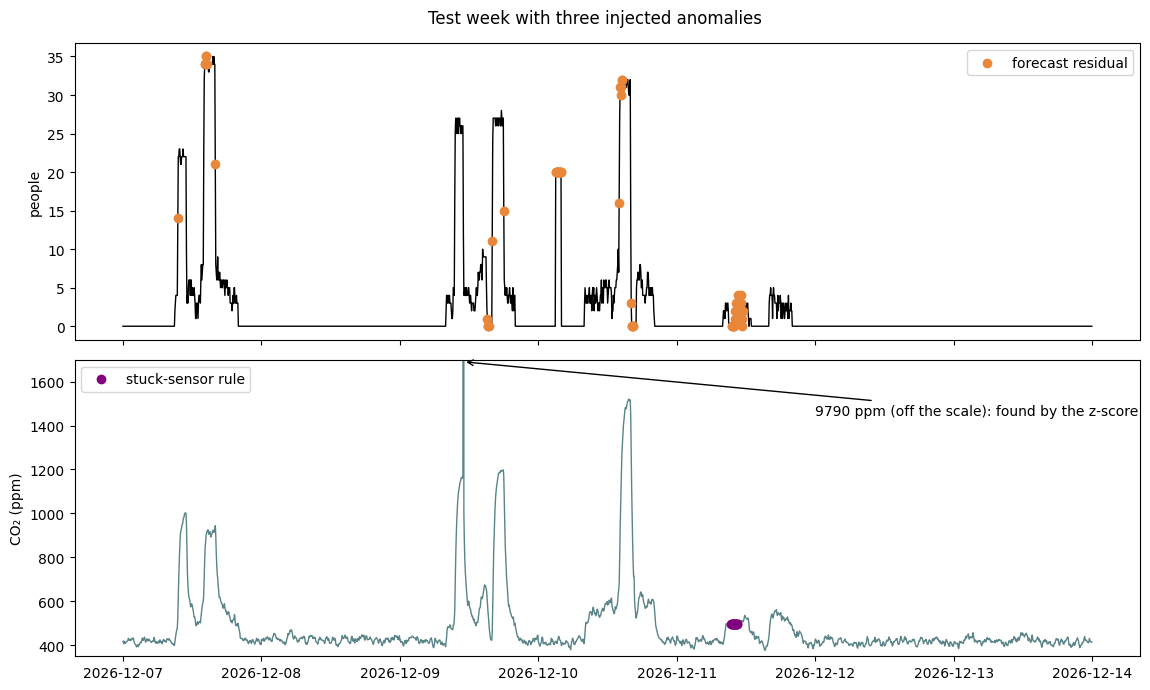

In [27]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(a.index, a['people'], color='black', lw=1); ax[0].set_ylabel('people')
fr = flag_res['people'].fillna(False)
ax[0].scatter(a.index[fr], a['people'][fr], color=ORANGE, label='forecast residual', zorder=3); ax[0].legend()
ax[1].plot(a.index, a['co2_ppm'], color=TEAL, lw=1); ax[1].set_ylabel('CO₂ (ppm)'); ax[1].set_ylim(350, 1700)
fs = flag_stuck['co2']
ax[1].scatter(a.index[fs], a['co2_ppm'][fs], color='purple', label='stuck-sensor rule', zorder=3)
ax[1].annotate('9790 ppm (off the scale): found by the z-score', xy=(injected['point (CO₂ 9790 ppm)'][0], 1690),
               xytext=(pd.Timestamp('2026-12-12'), 1450), arrowprops=dict(arrowstyle='->'))
ax[1].legend(); fig.suptitle('Test week with three injected anomalies'); plt.tight_layout(); plt.show()

**Questions for the class**
- Why does the z-score miss 20 people at 3 a.m.? (20 people at 3 p.m. is perfectly normal.)
- Why does no model find the stuck sensor, while a one-line rule does?
- Are the other orange points real anomalies or false alarms? How would you choose the threshold?

## Try it yourself
- forecast **60 minutes** ahead (`H = 12`): who suffers more?
- remove `lesson_next`, `last_week` or the Wi-Fi from the features of the boosted tree
- give the LSTM the `last_week` value too
- count the LSTM parameters: will it fit on the Arduino UNO Q? (Lesson 4!)